# Lab 1

### Setup  
Load target libs, dataset and define target columns

In [20]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

crashes = sns.load_dataset('car_crashes')
cols    = ['total', 'speeding', 'alcohol']

outliers_threshold = 3

### Define Z-Score solver

In [21]:
class ZScoreCalculator:
  def __init__(self, dataset):
    self.dataset = dataset

  def get_score(self, col):
    column = self.dataset[col]
    avg, std = np.nanmean(column), np.nanstd(column)
    return np.abs((column - avg) / std)

  def get_average_score(self, cols):
      z_scores = [self.get_score(col) for col in cols]
      z_matrix = np.vstack(z_scores).T    # pandas col indexation -> numpy row indexation
      return np.nansum(z_matrix, axis=1)
      # return np.sqrt(np.nansum(z_matrix ** 2, axis=1))

### Calculate Z-Scores

In [22]:
z_solver = ZScoreCalculator(crashes)

crashes['Z Score'] = z_solver.get_average_score(cols)
crashes['Is outlier'] = crashes['Z Score'] > outliers_threshold
outliers = crashes.loc[crashes['Is outlier']]

print(outliers.sort_values(by='Z Score', ascending=False).to_string())

    total  speeding  alcohol  not_distracted  no_previous  ins_premium  ins_losses abbrev   Z Score  Is outlier
40   23.9     9.082    9.799          22.944       19.359       858.97      116.29     SC  6.900224        True
8     5.9     2.006    1.593           5.900        5.900      1273.89      136.05     DC  5.844768        True
26   21.4     8.346    9.416          17.976       18.190       816.21       85.15     MT  5.695593        True
34   23.9     5.497   10.038          23.661       20.554       688.75      109.72     ND  5.245406        True
21    8.2     1.886    2.870           7.134        6.560      1011.14      135.63     MA  4.595429        True
48   23.8     8.092    6.664          23.086       20.706       992.61      152.56     WV  4.549106        True
23    9.6     2.208    2.784           8.448        8.448       777.18      133.35     MN  4.141468        True
11   17.5     9.450    7.175          14.350       15.225       861.18      120.92     HI  3.983704     

### Plot

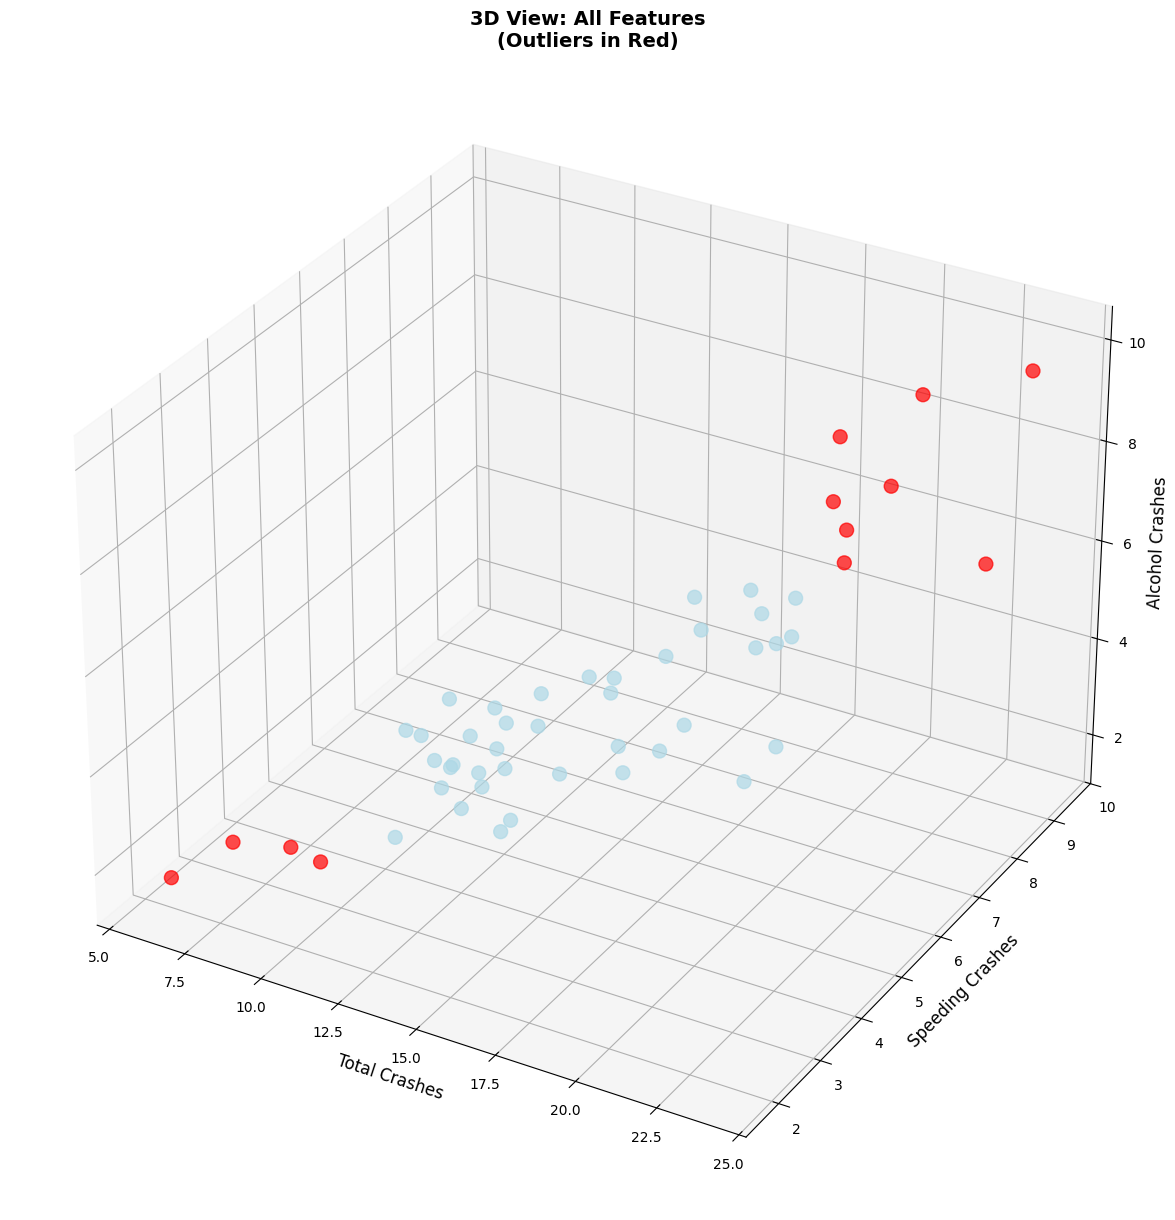

In [23]:
# Create figure with multiple subplots
fig = plt.figure(figsize=(20, 15))

# 3D Scatter Plot
ax = plt.subplot(1, 1, 1, projection='3d')
colors = ['red' if outlier else 'lightblue' for outlier in crashes['Is outlier']]
scatter = ax.scatter(crashes['total'], crashes['speeding'], crashes['alcohol'],
                     c=colors, s=100, alpha=0.7)
ax.set_xlabel('Total Crashes', fontsize=12)
ax.set_ylabel('Speeding Crashes', fontsize=12)
ax.set_zlabel('Alcohol Crashes', fontsize=12)
ax.set_title('3D View: All Features\n(Outliers in Red)', fontsize=14, fontweight='bold')

plt.show()